# MEROPS: stability of peptide rankings under count resampling

Retain the rank-stability analysis from the archived `0_01_merops_matrices.ipynb`. Test how much the ranking of a fixed peptide probe changes when the underlying positional counts are resampled.

## Introduction

**Assumptions and notation.** `N` code rows, `P=8` positions, `A=20` residues, `B` resamples, `I` probe peptides, `R=4` bond reductions. This is a conditional count bootstrap, not a permutation of peptide labels and not validation against measured cleavage sites or kinetics. Since only marginal counts are available, positions are resampled independently.

Inputs: the selected original MEROPS count/log-probability matrices, the existing human-proteome composition, and unique DBAASP sequences from `peptides_apex.csv`. No files are exported. All replicate-level results and selected probe rows stay in memory.

## Methodology

The existing helper draws a multinomial at each original positional depth, using its count frequencies smoothed with alpha=0.5; it then applies the same smoothing to the drawn matrix. This reproduces the old procedure, including both smoothing steps. It is a smoothed marginal resampling model, not a bootstrap of individual source cleavage events.

For every internal bond, sum `log p(residue | position) - log q(residue)` over positions present in the peptide. Reduce over bonds by `max`, `sum`, `mean` or `logsumexp`. For each code, reduction and resample, compute Spearman correlation between the probe's reference and resampled score rankings. The original helper assigns zero when either ranking is constant; these cases are counted separately below.

The human-proteome background is a fixed scoring reference, not a measured substrate-library composition for every MEROPS study. No enzyme-specific terminal geometry is imposed. This notebook measures the robustness of this scoring construction.

## What the four reductions mean

The input is the same peptide, the same matrix and the same score at each internal bond. Only the step that reduces all bond scores to one peptide score changes. These four rows are not four measured kinetic parameters or four kinds of cleavage.

| Reduction | Peptide score from bond scores `s1, ..., sJ` | Interpretation |
|---|---|---|
| `max` | largest bond score | The strongest local candidate dominates. |
| `sum` | sum of all bond scores | Adds evidence from every candidate bond; depends on peptide length. |
| `mean` | sum divided by the number of bonds | Average local score; one strong candidate can be diluted. |
| `logsumexp` | `log(sum(exp(sj)))` | Smooth maximum; several favourable candidates can contribute; also depends on the number of bonds. |

For example, bond scores `[-2, 1, 3]` give `max=3`, `sum=2`, `mean=0.667`, and `logsumexp≈3.133`. All quantities are scoring conventions, not rates.

For each resampled matrix, rank the same 1000 probe peptides again and compare the ranking with the original matrix using Spearman rho. A higher rho means that this convention changes its ranking less under this resampling model. The methods have no common measured accuracy target here: a more stable `sum` is not evidence that it predicts cleavage better than `max`.

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "src/pep_compass").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
RAW = ROOT / "data/proteolysis/window_neighbourhood_datasets/raw"
MEROPS = RAW / "merops"
pd.set_option("display.max_columns", None)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from pep_compass.steps.helpers.proteolysis import (
    BOND_REDUCTIONS, MEROPS_SMOOTHING_ALPHA, bootstrap_specificity_matrices,
    bootstrap_bond_reduction_rank_stability, load_amino_acid_background,
)

# Preserve the original scope, budget, seed and fixed probe.
DATASET_ID = 35
N_PROBE_PEPTIDES = 1000
N_BOOTSTRAP = 32
SEED = 20260920
PROBE_PATH = ROOT / "data/peptides_data/peptides_mic/peptides_apex.csv"
BACKGROUND_PATH = ROOT / "data/reference/human_proteome/composition.json"

index = json.loads((MEROPS / "index.json").read_text())
entry = index["by_index"][str(DATASET_ID)]
folder = MEROPS / entry["folder"]
metadata = json.loads((folder / "codes.json").read_text())
enzymes = pd.DataFrame(sorted(metadata["peptidases"], key=lambda item: item["row"]))
counts = np.load(folder / "matrices_counts.npy", allow_pickle=False)  # (N, P, A)
logprob = np.load(folder / "matrices_logprob.npy", allow_pickle=False)  # (N, P, A)
assert [item["row"] for item in sorted(metadata["peptidases"], key=lambda item: item["row"])] == list(range(len(enzymes)))
assert counts.shape == logprob.shape == (len(enzymes), 8, 20)
from pep_compass.steps.helpers.proteolysis import MEROPS_AMINO_ACIDS, MEROPS_SUBSITES
assert metadata["amino_acids"] == list(MEROPS_AMINO_ACIDS)
assert metadata["positions"] == list(MEROPS_SUBSITES)
expected = np.log((counts + MEROPS_SMOOTHING_ALPHA) /
                  (counts.sum(axis=-1, keepdims=True) + 20 * MEROPS_SMOOTHING_ALPHA))  # (N, P, A)
assert np.allclose(logprob, expected, atol=2e-6, rtol=0)
background = load_amino_acid_background(BACKGROUND_PATH)  # (A,)
probe_population = pd.read_csv(PROBE_PATH, usecols=["sequence", "dataset"])
probe_population = probe_population.loc[
    probe_population["dataset"].str.contains("dbaasp", case=False, na=False)
].drop_duplicates("sequence")
probe = probe_population.sample(n=N_PROBE_PEPTIDES, random_state=SEED)
probe_sequences = probe["sequence"].tolist()
assert probe["sequence"].str.fullmatch("[ACDEFGHIKLMNPQRSTVWY]{2,}").all()

# Reuse the current implementation, with one draw shared across all reductions.
replicate_matrices = bootstrap_specificity_matrices(counts, n_replicates=N_BOOTSTRAP, seed=SEED)  # (B, N, P, A)
reference_scores, stability = bootstrap_bond_reduction_rank_stability(
    probe_sequences, logprob, replicate_matrices, background=background,
)  # (R, I, N), (R, B, N)
stability_replicates = pd.DataFrame({
    "reduction": np.repeat(BOND_REDUCTIONS, N_BOOTSTRAP * len(enzymes)),
    "replicate": np.tile(np.repeat(np.arange(N_BOOTSTRAP), len(enzymes)), len(BOND_REDUCTIONS)),
    "code": np.tile(enzymes["code"], len(BOND_REDUCTIONS) * N_BOOTSTRAP),
    "spearman_rho": stability.ravel(),
})
summary_rows = []
for r, reduction in enumerate(BOND_REDUCTIONS):
    code_medians = np.median(stability[r], axis=0)  # (N,)
    summary_rows.append({
        "reduction": reduction, "code_rows": len(enzymes), "resamples_per_code": N_BOOTSTRAP,
        "median_code_median_rho": np.median(code_medians),
        "minimum_code_median_rho": code_medians.min(),
        "constant_reference_rankings": int((np.ptp(reference_scores[r], axis=0) == 0).sum()),
    })
stability_summary = pd.DataFrame(summary_rows)
display(stability_summary.round(3))

,reduction,code_rows,resamples_per_code,median_code_median_rho,minimum_code_median_rho,constant_reference_rankings
0,max,55,32,0.734,0.469,0
1,sum,55,32,0.938,0.853,0
2,mean,55,32,0.907,0.751,0
3,logsumexp,55,32,0.832,0.604,0


## Ranking variation by evidence depth

### Figure descriptions

Each point is one code under one reduction. The x-axis is its reported cleavage total; the y-axis is its median correlation across the 32 resamples. Vertical lines span the 10th–90th percentiles of those resamples: they describe variation under the resampling model, not confidence in biological validity. The second figure uses all per-code medians; each dot is one code, and the violin shows their distribution. Full resample values remain in `stability_replicates`.

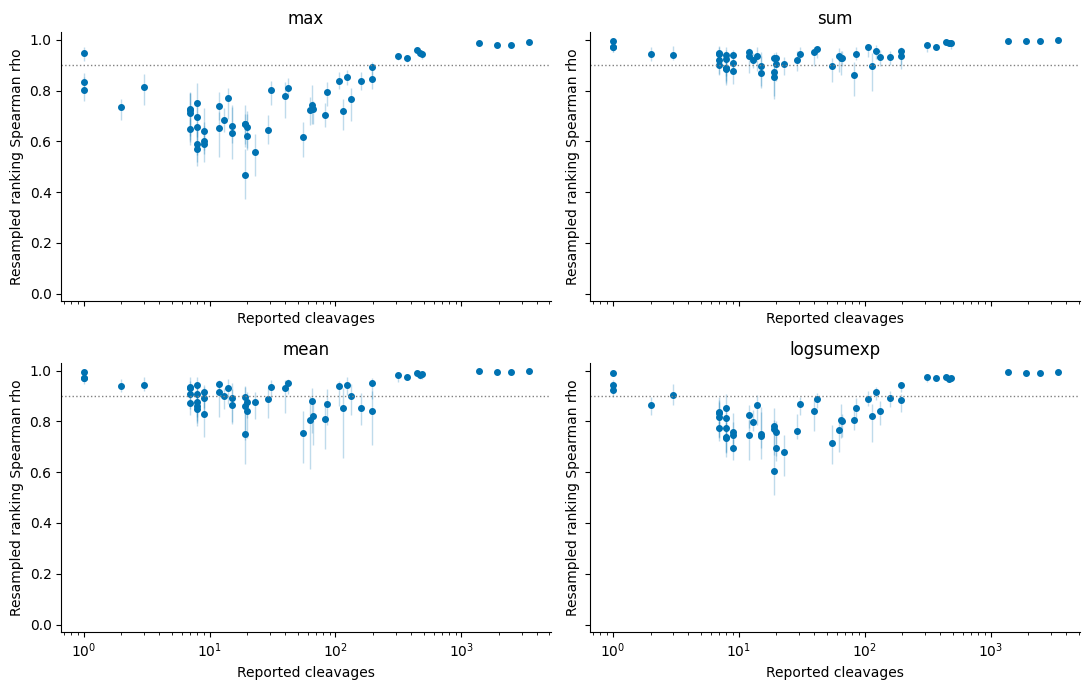

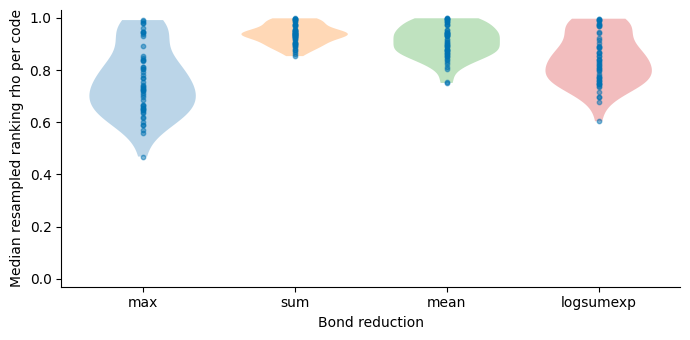

In [3]:
# Presentation settings do not change the resampling results.
FIGURE_SIZE = (11, 7)
REFERENCE_RHO = 0.9

fig, axes = plt.subplots(2, 2, figsize=FIGURE_SIZE, sharex=True, sharey=True)
for r, (ax, reduction) in enumerate(zip(axes.flat, BOND_REDUCTIONS)):
    low, median, high = np.quantile(stability[r], [0.1, 0.5, 0.9], axis=0)  # each (N,)
    ax.vlines(enzymes["n_cleavages"], low, high, color="#0072B2", alpha=0.25, linewidth=1)
    ax.scatter(enzymes["n_cleavages"], median, s=16, color="#0072B2")
    ax.axhline(REFERENCE_RHO, color="0.5", linestyle=":", linewidth=1)
    ax.set(xscale="log", title=reduction, xlabel="Reported cleavages", ylabel="Resampled ranking Spearman rho", ylim=(min(-0.03, float(stability.min()) - 0.03), 1.03))
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
for r, reduction in enumerate(BOND_REDUCTIONS):
    sample = np.median(stability[r], axis=0)  # (N,)
    if np.ptp(sample) > 0:
        ax.violinplot(sample, positions=[r], widths=0.7, showextrema=False)
    ax.scatter(np.full(len(sample), r), sample, s=10, alpha=0.5, color="#0072B2")
ax.set(xticks=range(len(BOND_REDUCTIONS)), xticklabels=BOND_REDUCTIONS,
       ylabel="Median resampled ranking rho per code", xlabel="Bond reduction", ylim=(min(-0.03, float(stability.min()) - 0.03), 1.03))
fig.tight_layout()
plt.show()

### Remarks

High rank stability does not establish a correct cleavage position or a kinetic relationship. `sum` and `logsumexp` depend on the number of candidate bonds. Independent positional resampling cannot recover correlations between residues of the same original event. The probe, background and all four reductions are kept identical to the old analysis.

### Notes

## Results / Summary

### LLM

For the default 55-code panel, median code-level median rho is 0.734 (`max`), 0.938 (`sum`), 0.907 (`mean`), and 0.832 (`logsumexp`), using 1000 fixed peptides and 32 resamples. These are score-stability results, not accuracy estimates.

Use the displayed resampling distribution to assess score sensitivity to the supplied count depth. Retain coverage and stability as separate attributes during integration; no automatic inclusion threshold is imposed here.

### Person

## Common numerical parameters

The common output is a positional probability matrix: each amino-acid column is its count divided by the observed positional total. Original overlapping profile populations remain separate. All transformations stay in memory; no CSV or database is written.

In [4]:
# Use the independent data library from this checkout.
import sys
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.integration.merge import (
    build_dataset, parse_dataset, add_merops_scores,
)
contract = parse_dataset("merops", ROOT / "data/proteolysis", data=[DATASET_ID])
probabilities = contract.position_probabilities()
display(probabilities[["source_db", "source_dataset", "merops_code", "position", "observed_weight", "A", "G", "L", "P"]].head(8))


,source_db,source_dataset,merops_code,position,observed_weight,A,G,L,P
0,merops,35,S01.228,P4,2.0,0.0,0.0,0.0,0.0
1,merops,35,S01.228,P3,2.0,0.0,0.0,0.0,0.0
2,merops,35,S01.228,P2,2.0,0.0,0.0,1.0,0.0
3,merops,35,S01.228,P1,2.0,0.0,0.0,0.0,0.0
4,merops,35,S01.228,P1p,2.0,0.0,0.0,0.0,0.0
5,merops,35,S01.228,P2p,2.0,0.0,0.0,0.0,0.0
6,merops,35,S01.228,P3p,2.0,0.0,0.5,0.0,0.0
7,merops,35,S01.228,P4p,2.0,0.0,1.0,0.0,0.0
